In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
df=pd.read_csv("../data/raw/collision_data.csv")

In [4]:
print(df.shape)

(101525, 44)


In [5]:
df.head()

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517H102225,2025,17H102225,449216.0,534979.0,-1.23770,54.70743,17,2,3,...,-1,0,2,1,2,E01033467,7,1,1.0,0.0
1,2025070815222,2025,070815222,363808.0,389192.0,-2.54576,53.39831,7,3,2,...,-1,0,1,2,2,E01012556,3,1,0.0,1.0
2,2025070937984,2025,070937984,362413.0,389071.0,-2.56673,53.39712,7,2,2,...,-1,0,1,3,2,E01012478,7,1,1.0,0.0
3,2025041687395,2025,041687395,368238.0,427802.0,-2.48308,53.74562,4,2,1,...,-1,0,1,1,2,E01012655,7,1,1.0,0.0
4,2025161555094,2025,161555094,510792.0,432167.0,-0.32035,53.77406,16,3,2,...,-1,0,1,1,2,E01012815,3,1,0.0,1.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101525 entries, 0 to 101524
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   101525 non-null  str    
 1   collision_year                                    101525 non-null  int64  
 2   collision_ref_no                                  101525 non-null  str    
 3   location_easting_osgr                             101523 non-null  float64
 4   location_northing_osgr                            101523 non-null  float64
 5   longitude                                         101523 non-null  float64
 6   latitude                                          101523 non-null  float64
 7   police_force                                      101525 non-null  int64  
 8   collision_severity                                101525 non-null  int64  
 9   number_of_vehic

In [7]:
df.columns.tolist()

['collision_index',
 'collision_year',
 'collision_ref_no',
 'location_easting_osgr',
 'location_northing_osgr',
 'longitude',
 'latitude',
 'police_force',
 'collision_severity',
 'number_of_vehicles',
 'number_of_casualties',
 'date',
 'day_of_week',
 'time',
 'local_authority_district',
 'local_authority_ons_district',
 'local_authority_highway',
 'local_authority_highway_current',
 'first_road_class',
 'first_road_number',
 'road_type',
 'speed_limit',
 'junction_detail_historic',
 'junction_detail',
 'junction_control',
 'second_road_class',
 'second_road_number',
 'pedestrian_crossing_human_control_historic',
 'pedestrian_crossing_physical_facilities_historic',
 'pedestrian_crossing',
 'light_conditions',
 'weather_conditions',
 'road_surface_conditions',
 'special_conditions_at_site',
 'carriageway_hazards_historic',
 'carriageway_hazards',
 'urban_or_rural_area',
 'did_police_officer_attend_scene_of_accident',
 'trunk_road_flag',
 'lsoa_of_accident_location',
 'enhanced_severit

In [8]:
df.isna().sum().sort_values(ascending=False)

location_easting_osgr                               2
latitude                                            2
longitude                                           2
location_northing_osgr                              2
collision_ref_no                                    0
collision_year                                      0
collision_index                                     0
police_force                                        0
collision_severity                                  0
number_of_vehicles                                  0
number_of_casualties                                0
date                                                0
day_of_week                                         0
time                                                0
local_authority_district                            0
local_authority_ons_district                        0
local_authority_highway                             0
local_authority_highway_current                     0
first_road_class            

In [15]:
print(set(df["collision_severity"].values))
df["collision_severity"].value_counts()

{np.int64(1), np.int64(2), np.int64(3)}


collision_severity
3    74881
2    25191
1     1453
Name: count, dtype: int64

In [11]:
df["collision_severity"].value_counts(normalize=True)*100

collision_severity
3    73.756218
2    24.812608
1     1.431175
Name: proportion, dtype: float64

In [16]:
for col in df.columns:
    print(
        f"{col:50} "
        f"unique={df[col].nunique():8} "
        f"missing={df[col].isna().sum():6}"
    )

collision_index                                    unique=  101525 missing=     0
collision_year                                     unique=       1 missing=     0
collision_ref_no                                   unique=  101525 missing=     0
location_easting_osgr                              unique=   83236 missing=     2
location_northing_osgr                             unique=   83768 missing=     2
longitude                                          unique=   88044 missing=     2
latitude                                           unique=   82164 missing=     2
police_force                                       unique=      44 missing=     0
collision_severity                                 unique=       3 missing=     0
number_of_vehicles                                 unique=      13 missing=     0
number_of_casualties                               unique=      21 missing=     0
date                                               unique=     365 missing=     0
day_of_week     

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
collision_year,101525.0,2025.000000,0.000000,2025.00000,2025.00000,2025.00000,2025.00000,2.025000e+03
location_easting_osgr,101523.0,454027.068812,92739.506456,71253.00000,392107.50000,458353.00000,529150.50000,6.551260e+05
location_northing_osgr,101523.0,276459.222127,145214.997315,10237.00000,175365.00000,222829.00000,381393.50000,1.162591e+06
longitude,101523.0,-1.223959,1.356983,-7.41772,-2.11870,-1.13891,-0.13791,1.755590e+00
latitude,101523.0,52.375658,1.308239,49.91253,51.46446,51.88864,53.32586,6.034525e+01
police_force,101525.0,27.962522,24.075091,1.00000,5.00000,23.00000,45.00000,9.900000e+01
collision_severity,101525.0,2.723250,0.478315,1.00000,2.00000,3.00000,3.00000,3.000000e+00
number_of_vehicles,101525.0,1.811849,0.689631,1.00000,1.00000,2.00000,2.00000,1.700000e+01
number_of_casualties,101525.0,1.259621,0.816679,1.00000,1.00000,1.00000,1.00000,1.420000e+02
day_of_week,101525.0,4.126097,1.926299,1.00000,2.00000,4.00000,6.00000,7.000000e+00


In [18]:
severity_map = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

df["severity_name"] = df["collision_severity"].map(severity_map)

In [23]:
df["severity_name"].value_counts()

severity_name
Slight     74881
Serious    25191
Fatal       1453
Name: count, dtype: int64

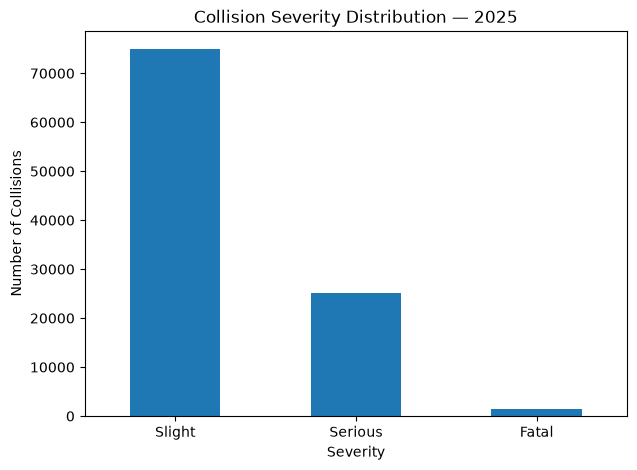

In [26]:
severity_counts = df["severity_name"].value_counts()

plt.figure(figsize=(7, 5))
severity_counts.plot(kind="bar")

plt.title("Collision Severity Distribution — 2025")
plt.xlabel("Severity")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=0)

plt.show()

In [27]:
important_cols = [
    "road_type",
    "speed_limit",
    "junction_detail",
    "junction_control",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area",
    "trunk_road_flag"
]

for col in important_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().sort_index())


--- road_type ---
road_type
1     6795
2     2398
3    14610
6    74150
7     1619
9     1953
Name: count, dtype: int64

--- speed_limit ---
speed_limit
20    20045
30    49673
40     8886
50     4612
60    12709
70     5600
Name: count, dtype: int64

--- junction_detail ---
junction_detail
-1      6701
 0     45333
 13    28198
 16     9456
 17     1504
 18     2144
 19     6762
 99     1427
Name: count, dtype: int64

--- junction_control ---
junction_control
-1    44487
 1      381
 2    10580
 3      649
 4    41902
 9     3526
Name: count, dtype: int64

--- light_conditions ---
light_conditions
-1       16
 1    72814
 4    20705
 5      720
 6     5682
 7     1588
Name: count, dtype: int64

--- weather_conditions ---
weather_conditions
1    83405
2    10230
3      235
4      715
5      880
6       19
7      342
8     3314
9     2385
Name: count, dtype: int64

--- road_surface_conditions ---
road_surface_conditions
-1      634
 1    75679
 2    22312
 3      146
 4     1261
 5    

In [30]:
for col in df.select_dtypes(include="number").columns:
    unknown_count = df[col].isin([-1, 99]).sum()
    
    if unknown_count > 0:
        print(
            f"{col:50} "
            f"unknown_like={unknown_count:6} "
            f"({unknown_count / len(df) * 100:.2f}%)"
        )

police_force                                       unknown_like=  4104 (4.04%)
local_authority_district                           unknown_like=101525 (100.00%)
first_road_class                                   unknown_like=     6 (0.01%)
first_road_number                                  unknown_like=     9 (0.01%)
junction_detail_historic                           unknown_like= 88146 (86.82%)
junction_detail                                    unknown_like=  8128 (8.01%)
junction_control                                   unknown_like= 44487 (43.82%)
second_road_class                                  unknown_like=   171 (0.17%)
second_road_number                                 unknown_like= 25105 (24.73%)
pedestrian_crossing_human_control_historic         unknown_like= 87852 (86.53%)
pedestrian_crossing_physical_facilities_historic   unknown_like= 87851 (86.53%)
pedestrian_crossing                                unknown_like=  6828 (6.73%)
light_conditions                             

In [32]:
pd.crosstab(df["junction_detail"], df["junction_control"])

junction_control,-1,1,2,3,4,9
junction_detail,,,,,,
-1,257,39,1053,35,5023,294
0,43155,11,278,9,1560,320
13,347,164,3091,282,23033,1281
16,80,62,4256,214,4568,276
17,17,18,671,25,747,26
18,237,10,51,5,1745,96
19,351,75,996,69,5116,155
99,43,2,184,10,110,1078


In [33]:
df[
    [
        "junction_detail_historic",
        "junction_detail",
        "pedestrian_crossing_human_control_historic",
        "pedestrian_crossing",
        "carriageway_hazards_historic",
        "carriageway_hazards"
    ]
].head(30)

,junction_detail_historic,junction_detail,pedestrian_crossing_human_control_historic,pedestrian_crossing,carriageway_hazards_historic,carriageway_hazards
0,-1,-1,-1,0,-1,0
1,-1,13,-1,0,-1,0
2,-1,16,-1,14,-1,0
3,-1,0,-1,0,-1,0
4,-1,0,-1,0,-1,0
5,-1,16,-1,0,-1,0
6,-1,16,-1,0,-1,0
7,-1,19,-1,0,-1,0
8,-1,13,-1,0,-1,0
9,-1,0,-1,0,-1,0


In [34]:
df[
    [
        "junction_detail_historic",
        "junction_detail",
        "pedestrian_crossing_human_control_historic",
        "pedestrian_crossing",
        "carriageway_hazards_historic",
        "carriageway_hazards"
    ]
].head(30)

,junction_detail_historic,junction_detail,pedestrian_crossing_human_control_historic,pedestrian_crossing,carriageway_hazards_historic,carriageway_hazards
0,-1,-1,-1,0,-1,0
1,-1,13,-1,0,-1,0
2,-1,16,-1,14,-1,0
3,-1,0,-1,0,-1,0
4,-1,0,-1,0,-1,0
5,-1,16,-1,0,-1,0
6,-1,16,-1,0,-1,0
7,-1,19,-1,0,-1,0
8,-1,13,-1,0,-1,0
9,-1,0,-1,0,-1,0


In [ ]:
analysis_df = df.copy()

drop_cols = [
    "collision_index",
    "collision_ref_no",
    "collision_year",
    "local_authority_district",
    "junction_detail_historic",
    "pedestrian_crossing_human_control_historic",
    "pedestrian_crossing_physical_facilities_historic",
    "carriageway_hazards_historic",
    "special_conditions_at_site",
    "enhanced_severity_collision",
    "collision_injury_based",
    "collision_adjusted_severity_serious",
    "collision_adjusted_severity_slight"
]

analysis_df = analysis_df.drop(columns=drop_cols)

In [37]:
for col in [
    "junction_detail",
    "junction_control",
    "pedestrian_crossing",
    "carriageway_hazards",
    "road_type",
    "light_conditions",
    "weather_conditions",
    "road_surface_conditions",
    "urban_or_rural_area"
]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts().sort_index())


--- junction_detail ---
junction_detail
-1      6701
 0     45333
 13    28198
 16     9456
 17     1504
 18     2144
 19     6762
 99     1427
Name: count, dtype: int64

--- junction_control ---
junction_control
-1    44487
 1      381
 2    10580
 3      649
 4    41902
 9     3526
Name: count, dtype: int64

--- pedestrian_crossing ---
pedestrian_crossing
-1      6527
 0     74538
 11      257
 12      573
 13     3757
 14     6591
 15     6040
 16      184
 17     2757
 99      301
Name: count, dtype: int64

--- carriageway_hazards ---
carriageway_hazards
-1      5346
 0     91375
 11      277
 12      243
 13     1042
 14      123
 15      318
 16      123
 17      881
 18      164
 19      161
 20      271
 21      506
 99      695
Name: count, dtype: int64

--- road_type ---
road_type
1     6795
2     2398
3    14610
6    74150
7     1619
9     1953
Name: count, dtype: int64

--- light_conditions ---
light_conditions
-1       16
 1    72814
 4    20705
 5      720
 6     5682
 7

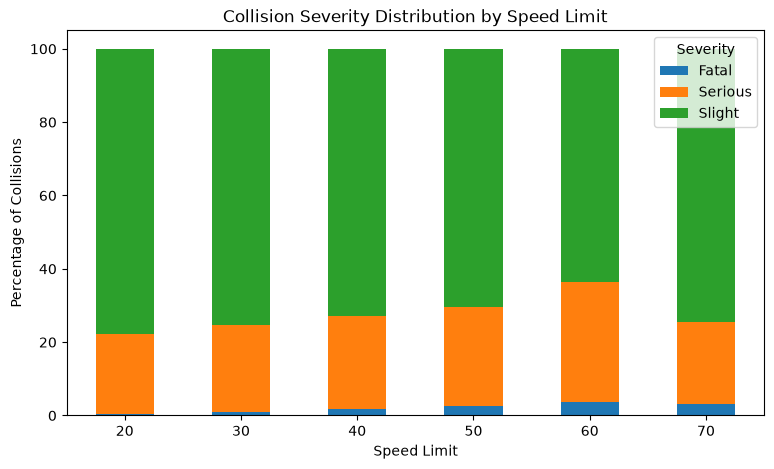

In [39]:
speed_severity = pd.crosstab(
    analysis_df["speed_limit"],
    analysis_df["severity_name"],
    normalize="index"
) * 100

speed_severity.round(2)

speed_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Collision Severity Distribution by Speed Limit")
plt.xlabel("Speed Limit")
plt.ylabel("Percentage of Collisions")
plt.xticks(rotation=0)
plt.legend(title="Severity")

plt.show()


In [40]:
pd.crosstab(
    df["speed_limit"],
    df["urban_or_rural_area"],
    normalize="index"
).round(3) * 100


urban_or_rural_area,1,2,3
speed_limit,,,
20,94.2,5.8,0.0
30,84.5,15.5,0.0
40,47.3,52.7,0.0
50,21.1,78.9,0.0
60,2.9,97.1,0.0
70,13.4,86.6,0.0


In [41]:
pd.crosstab(
    df["speed_limit"],
    df["road_type"],
    normalize="index"
).round(3) * 100

road_type,1,2,3,6,7,9
speed_limit,,,,,,
20,3.9,7.5,7.4,74.4,1.1,5.7
30,7.6,1.7,7.9,80.3,1.0,1.5
40,12.4,0.3,27.2,57.8,2.0,0.3
50,7.6,0.1,29.4,59.8,2.9,0.2
60,4.1,0.1,4.5,90.3,1.0,0.1
70,5.0,0.0,86.3,0.0,8.3,0.3


In [ ]:
df["killed_or_serious"] = (
    df["collision_severity"].isin([1, 2])
).astype(int)

single_road=df[df["road_type"]==6]

single_speed_risk=(single_road
                   .groupby("speed_limit")["killed_or_serious"]
                   .agg(ksi_rate="mean",collision_count="count")
                   .assign(mean=lambda x: x["ksi_rate"]*100))

single_speed_risk

,mean,count
speed_limit,,
20,23.511665,14916
30,25.877248,39869
40,30.872614,5134
50,35.304790,2756
60,37.690632,11475


In [44]:
rural_single = df[
    (df["road_type"] == 6) &
    (df["urban_or_rural_area"] == 2)
]

(
    rural_single
    .groupby("speed_limit")["killed_or_serious"]
    .agg(["mean", "count"])
    .assign(mean=lambda x: x["mean"]*100)
)

,mean,count
speed_limit,,
20,28.838583,1016
30,27.030016,6330
40,31.409513,3448
50,35.747304,2596
60,37.814382,11292


In [57]:
road_risk = (
    df.groupby("road_type")["killed_or_serious"]
      .agg(["mean", "count"])
)

road_risk["mean"] *= 100

road_risk.sort_values("mean", ascending=False)

,mean,count
road_type,,
6,27.925826,74150
3,24.558522,14610
2,20.558799,2398
7,20.012353,1619
1,19.470199,6795
9,10.701485,1953


In [58]:
df["light_conditions"].value_counts().sort_index()

light_conditions
-1       16
 1    72814
 4    20705
 5      720
 6     5682
 7     1588
Name: count, dtype: int64

In [ ]:
light_risk=(df.groupby("light_conditions")
              .agg(ksi_rate="mean",collision_count="count"))
light_risk